In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random as rd
import os

In [39]:
df = pd.read_csv('CNMFe_001.csv')

cols = df.loc[0].eq(" accepted")
cols = cols.index[cols]
cols = list(cols)

df_data = df[[" ",*cols]].drop([0])
df_data = df_data.astype(np.double)
df_data.loc[6005:,' '] -= 216
df_data.loc[12010:,' '] -= 246
df_data = df_data.drop([287])
df_data.describe()

C:\Users\stefa\AppData\Local\Programs\Python\Python39\lib\site-packages\IPython\core\interactiveshell.py:3437: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,,C00,C03,C06,C07,C08,C09,C10,C11,C12,...,C52,C53,C54,C60,C61,C62,C83,C84,C87,C88
count,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,...,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000
mean,449.689788,3.235596,6.809554,2.931266,8.068414,4.939414,2.045662,4.589893,1.746835,4.175543,...,16.996311,5.468160,4.309018,11.587155,3.383830,5.845208,2.562680,2.293834,18.419469,8.709112
std,259.463129,5.037583,11.609843,4.265323,7.240192,6.181540,4.298476,5.423342,3.298945,3.512614,...,21.948460,9.373994,5.499845,10.437031,6.423637,6.672227,5.509474,4.872615,27.405002,15.954859
min,0.000000,-9.396105,-6.844311,-4.141964,-28.953090,-8.164639,-16.472150,-6.252151,-5.656444,-8.766191,...,-9.281466,-10.102720,-16.183490,-18.464750,-3.636737,-5.645173,-4.141433,-5.246032,1.605962,-3.741021
25%,225.011854,1.173485,1.588636,0.721529,2.826491,2.192229,0.345608,1.469635,0.059988,2.421564,...,3.763016,2.406611,2.302440,4.578631,0.736214,2.762172,0.299067,0.080744,4.290992,1.360675
50%,449.964902,2.009636,2.278298,1.919267,7.368660,3.145020,1.244413,2.421317,0.996585,3.942240,...,9.460235,3.477733,3.640115,7.871584,1.747806,3.647002,1.189227,0.937819,8.760721,4.040163
75%,674.094990,3.162544,4.069437,3.391791,12.650365,4.662193,2.280474,4.921967,2.153277,5.251800,...,21.328020,5.069334,5.029612,15.284215,3.210670,5.055882,2.265223,2.106726,18.884058,9.129316
max,899.056883,48.045680,70.556780,30.992870,37.657430,55.530590,40.501240,30.907140,24.657250,59.188320,...,154.100000,126.603700,105.928200,70.648000,63.544250,44.301010,53.883000,36.530460,223.406100,171.017900


In [43]:
df_s = pd.read_csv("spikes_deconvolve_CNMFe_001.csv")
S_vals = df_s.transpose().to_numpy()
S_vals = S_vals[1:]
for i, el in enumerate(S_vals):
    leng = len([i for i in el if i>0])
    print(f'Column{cols[i]} has {leng} spikes')

Column C00 has 502 spikes
Column C03 has 534 spikes
Column C06 has 640 spikes
Column C07 has 2547 spikes
Column C08 has 538 spikes
Column C09 has 250 spikes
Column C10 has 985 spikes
Column C11 has 956 spikes
Column C12 has 351 spikes
Column C15 has 398 spikes
Column C18 has 501 spikes
Column C19 has 846 spikes
Column C21 has 509 spikes
Column C24 has 23 spikes
Column C25 has 426 spikes
Column C27 has 903 spikes
Column C28 has 759 spikes
Column C32 has 977 spikes
Column C38 has 619 spikes
Column C52 has 981 spikes
Column C53 has 229 spikes
Column C54 has 248 spikes
Column C60 has 1562 spikes
Column C61 has 392 spikes
Column C62 has 787 spikes
Column C83 has 340 spikes
Column C84 has 323 spikes
Column C87 has 517 spikes
Column C88 has 189 spikes


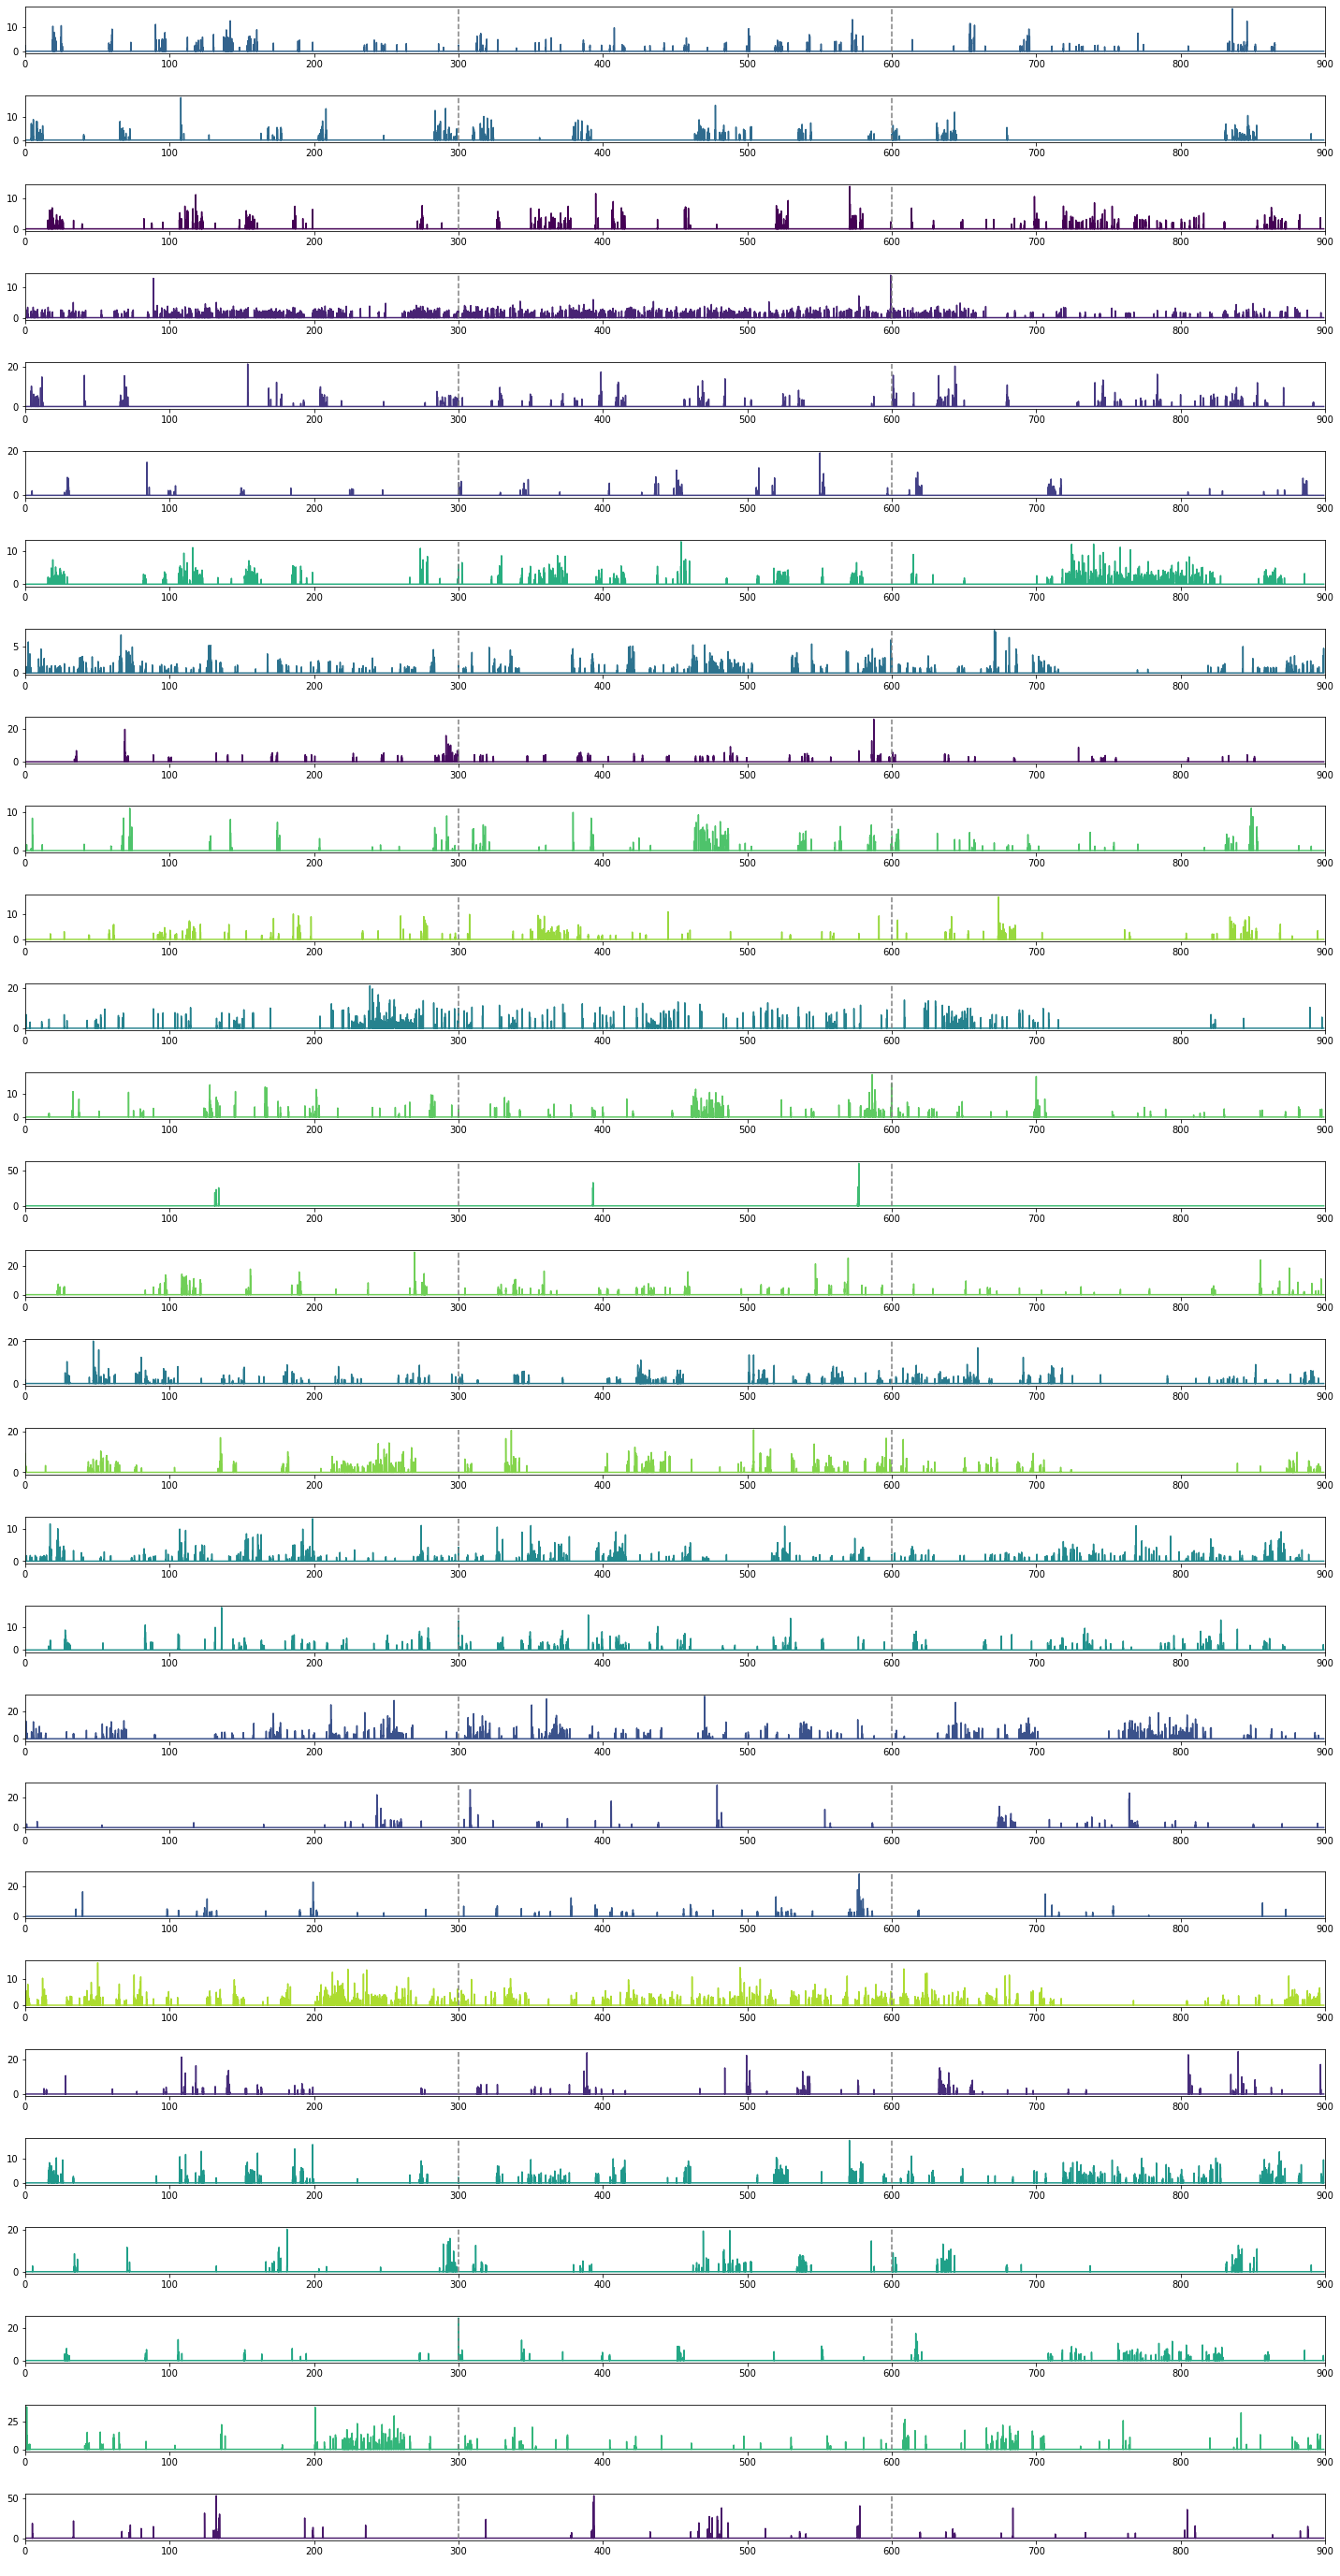

In [44]:
palette = sns.color_palette('viridis',as_cmap=True).colors

step = int(len(palette)/len(cols))

palette_r = sns.color_palette("bright")

# UNCOMMENT THIS LINE TO MAKE ALL TRACES BLACK
# palette = ['#000' for i in range(len(palette))]

fig, ax = plt.subplots(len(cols), 1)
fig = plt.gcf()
fig.set_size_inches([20,len(cols)*1.322])

color_indices = [i*step for i in range(len(cols))]
rd.shuffle(color_indices)
#Shuffle colors
# color_indices = [0, 100, 25, 200, 50, 175, 75, 125, 150, 225]

for i in range(len(cols)):
    
    max_val = S_vals[i].max()
    min_val = S_vals[i].min()
    
    sns.lineplot(data=df_data,x=" ",y=S_vals[i],ax=ax[i],color=palette[color_indices[i]])
    ax[i].plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
    ax[i].plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')
    
    ax[i].set_xlim([0,900])
    
fig.tight_layout()
fig.savefig("CNMFE_deconvolve_only.jpg",dpi=500)